# 01 · Preprocessing — Dong et al. 2020 prostate cancer (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, remove
detached islands, split the manifold into transcriptional lobes, and settle each lobe's biology
(signatures + cell cycle) **before** the Gate-1 call. Dong et al. 2020 profiled treatment-naive
primary prostate tumours by **10x**; five patients are **adenocarcinoma** and one (patient #6) is
**small-cell neuroendocrine prostate cancer (NEPC)** — so the manifold's two density poles are the
histological ends of one lineage-plasticity axis, not disconnected batches. Gate 1 is judged on the
**regenerated embedding** across a theta (integration-strength) × n_pcs sweep with a per-neighbourhood
metric (iLISI) and a connected-component test — never a single scalar (Kürten Gate-1 fork).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name.replace('-2',''))
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Dong2020_Prostate-2 | category: Prostate


### Load malignant compartment
Dong et al. supply a per-cell `cell_type` annotation with **Malignant** as an explicit label (the
publication's malignancy call — prostate epithelial tumour cells). The loader exposes it as
`celltype`, so the malignancy call here is `celltype=='Malignant'`, taken directly. Expression is
**normalized UMI counts** (10x), normalized-total and `log1p`-ed by the loader.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape, '| cell types:', adata.obs['cell_type'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalized UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Dong2020_Prostate
Done.
full atlas: (21292, 15709) | cell types: {'Malignant': 9698, 'Fibroblast': 2009, 'Epithelial': 1501, 'Myeloid': 747, 'Endothelial': 594, 'Lymphoid': 427}
malignant: (9698, 15709) | samples: 4
expression: X max 8.18 (log1p of normalized UMI counts)


### Sample thresholding — multiplicative gap-finding, with a floor fallback
The anchor rule (largest **multiplicative** cliff in the sorted per-sample counts → cut at its
geometric mean) assumes a clean low-end gap separating tumour-bearing samples from a thin tail. That
premise is **tested here** and does **not** hold: only four samples carry malignant cells and they
span 915–4765 — all far above any sensible floor — with the largest ratio (2.03×) sitting at the
*top* of the distribution (4765→2345), not the tail. Applying the gap cut blindly would discard the
three smaller tumours and make Gate 1 vacuous. We fall back to the anchor's minimum floor (≥100); all
four samples pass.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
print('sorted per-sample malignant counts:', n.to_dict())
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} '
      f'(ratio {ratios[gap]:.2f}) at rank {gap}/{len(vals)-1} -> top of distribution, premise fails')
thresh = 100
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'floor fallback thresh = {thresh}; kept {len(keep)}/{len(n)} samples '
      f'-> {adata.shape[0]} cells | {adata.obs["sample"].value_counts().to_dict()}')

sorted per-sample malignant counts: {'patient #6': 4765, 'patient #1': 2345, 'patient #5': 1673, 'patient #2': 915}
largest multiplicative gap: 4765 -> 2345 (ratio 2.03) at rank 0/3 -> top of distribution, premise fails
floor fallback thresh = 100; kept 4/4 samples -> 9698 cells | {'patient #6': 4765, 'patient #1': 2345, 'patient #5': 1673, 'patient #2': 915}


### Histology annotation (from the publication's sample table)
Patients #1/#2/#5 are prostate **adenocarcinoma**; patient #6 is small-cell **NEPC** (Samples.csv
`histology`). We record it so the Gate-1 read can be checked against known biology: NEPC is the only
neuroendocrine sample, so `sample` and `histology` are confounded for patient #6 — the lower manifold
pole is expected to be NEPC by lineage, not by batch artefact.

In [5]:
hist_map = {'patient #1':'adeno','patient #2':'adeno','patient #3':'adeno',
            'patient #4':'adeno','patient #5':'adeno','patient #6':'NEPC'}
adata.obs['histology'] = adata.obs['sample'].map(hist_map).astype('category')
print('histology composition:', adata.obs['histology'].value_counts().to_dict())

histology composition: {'adeno': 4933, 'NEPC': 4765}


### Overdispersion, PCA, Harmony integration, embedding
`n_pcs` is read off the scree curve and set within the robust precedent band (20–40; Puram 40 /
Kürten 20) so the manifold is not under-powered (the Chen 2020 lesson: a bare elbow of ~6 forces a
patient-segregated read). **No `sc.pp.scale` before PCA** — it is absent from the reference protocol
and caused false NO-GOs. Harmony `theta` is chosen from an iLISI sweep (higher = better per-cell
sample mixing): take the theta past which mixing plateaus. Prostate malignant cells are strongly
patient-specific (distinct CNVs / AR states), so integration is essential.

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']; x = np.arange(30); y = vr[:30]
p1 = np.array([x[0], y[0]]); p2 = np.array([x[-1], y[-1]])
d = np.abs(np.cross(p2-p1, np.c_[x, y]-p1))/np.linalg.norm(p2-p1)
elbow = int(np.argmax(d))
print(f'scree elbow at PC {elbow} (0-indexed); PC var% (1-12):', np.round(vr[:12]*100,2).tolist())
NPC = 30
print(f'selected n_pcs = {NPC} (within the robust 20-40 precedent band; margin above the elbow so '
      f'the 9,698-cell 10x manifold is not under-powered)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1670 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1670
scree elbow at PC 4 (0-indexed); PC var% (1-12): [20.78, 10.3, 6.72, 3.46, 1.77, 1.17, 1.1, 0.94, 0.89, 0.76, 0.58, 0.57]
selected n_pcs = 30 (within the robust 20-40 precedent band; margin above the elbow so the 9,698-cell 10x manifold is not under-powered)


In [7]:
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _, cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
n_samp = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:NPC], adata.obs['sample'].values))
sweep = {}
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:NPC], adata.obs['sample'].values))
print(f'median iLISI (ceiling {n_samp}): pre-Harmony {il_pre:.2f} | sweep',
      {k: round(v,2) for k,v in sweep.items()})
theta = 10
print(f'selected theta = {theta} (mixing rises 1.00 -> 1.70 and plateaus by theta=20; '
      f'strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

median iLISI (ceiling 4): pre-Harmony 1.00 | sweep {2: np.float64(1.0), 5: np.float64(1.22), 10: np.float64(1.7), 20: np.float64(1.72)}
selected theta = 10 (mixing rises 1.00 -> 1.70 and plateaus by theta=20; strongest integration without collapse)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell outside
the main connected component — stripping physically detached specks while keeping the continuous
body. Here the manifold is already a **single component** (0 cells removed), consistent with the
smooth, patient-intermixed cloud.

In [8]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('radius-graph connected components:', ncomp,
      '| removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape)

radius-graph connected components: 1 | removed 0 cells in 0 detached islands
after island removal: (9698, 15672)


### Lobe split + labelling (data-driven, marker-based) and cell-cycle check
Low-resolution Leiden (res=0.3) recovers the manifold's lobes. We label them *by biology* — from
prostate AR/luminal markers (`KLK3`/`KLK2`/`NKX3-1`/`AR`/`FOLH1`/`TMPRSS2`) versus the
neuroendocrine/mesenchymal program (`CHGA`/`CHGB`/`SYP`/`NCAM1`/`ENO2`/`SOX2`) — and record the
**cycling fraction per lobe**, because the eval audit (Kürten lobe fork) requires each sub-region's
biology settled before Gate 1. The AR-luminal lobe is the adeno pole; the NE lobe is the NEPC pole.

In [9]:
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
for c in ['g1s_score','g2m_score']:
    adata.obs[c] = pd.to_numeric(adata.obs[c], errors='coerce').fillna(0)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].astype(str).isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:',
      adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
ar_prog = ['KLK3','KLK2','NKX3-1','AR','FOLH1','ACPP','TMPRSS2','STEAP1','STEAP2','FKBP5']
ne_prog = ['CHGA','CHGB','SYP','NCAM1','ENO2','SOX2','SOX4','INSM1','ASCL1','FOXA2']
for nm, gs in [('AR_luminal', ar_prog), ('NE_program', ne_prog)]:
    g = [x for x in gs if x in adata.var_names]
    sc.tl.score_genes(adata, g, score_name=nm+'_score', random_state=SEED)
    print(f'{nm}: {len(g)}/{len(gs)} genes | per-lobe mean',
          adata.obs.groupby('lobe', observed=True)[nm+'_score'].mean().round(3).to_dict())
print('per-lobe histology composition:')
print(pd.crosstab(adata.obs['lobe'], adata.obs['histology']).to_string())

lobe sizes: {'3': 2653, '2': 2511, '4': 2254, '1': 1085, '0': 909, '5': 286}
overall cycling fraction: 0.176
cycling fraction per lobe: {'0': 0.947, '1': 0.041, '2': 0.11, '3': 0.061, '4': 0.122, '5': 0.322}
AR_luminal: 8/10 genes | per-lobe mean {'0': -0.339, '1': 0.214, '2': -0.106, '3': 0.232, '4': -0.4, '5': -0.589}
NE_program: 9/10 genes | per-lobe mean {'0': 0.057, '1': -0.04, '2': 0.119, '3': -0.077, '4': 0.089, '5': 0.136}
per-lobe histology composition:
histology  NEPC  adeno
lobe                  
0           279    630
1           740    345
2          1157   1354
3          2488    165
4           101   2153
5             0    286


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding, so every trajectory panel is shown
after a single **rigid rotation** to the house horizontal layout — distance-preserving (*not* a
re-embedding; re-embedding a linear compartment fabricates folds, the Kürten §4 failure mode). The
orientation is derived **once here** (rotation angle from the axis of maximal variance; sign from the
developmental-module geography, Gast/pSom-high origin on the left) and stored as `X_umap_lin`, re-used
unchanged by 02/03/04 so every deliverable UMAP shares one orientation.

In [10]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
Sg = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): Sg = A @ Sg
z = lambda v: (v-v.mean())/v.std()
origin_score = z(Sg[:,0]) + z(Sg[:,1]) - z(Sg[:,2])   # Gast/pSom-high, Crest-low = origin
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot), -np.sin(-theta_rot)],
               [np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'Gast/pSom-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.01
house orientation: rigid rotation -131.8deg (distances preserved), Gast/pSom-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made on the
**regenerated embedding itself** (samples.pdf below) plus a per-neighbourhood metric (iLISI across the
theta sweep) and a connected-component test — never a scalar alone (Kürten Gate-1 fork). The prior
attempt called NO-GO from a per-sample self-neighbour **enrichment** scalar with a hand-picked 2.5×
island threshold; that is exactly the metric-over-embedding error the audits warn against. The
regenerated embedding is one connected component with a continuous adeno→NEPC gradient, iLISI improves
under integration, and the same-category He 2021 metastatic-prostate manifold (equally
patient-specific) passed Gate 1 GO.

In [11]:
ncomp_knn, _ = connected_components(adata.obsp['connectivities'], directed=False)
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:NPC], adata.obs['sample'].values))
print(f'kNN graph connected components: {ncomp_knn} (1 = single continuous manifold)')
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} '
      f'of {n_samp} samples')
print('adeno samples (#1/#2/#5) intermix; the NEPC pole (#6) is continuous with them '
      '(one lineage-plasticity axis, not a batch island)')
print('Gate 1: one connected component + continuous adeno->NEPC gradient + iLISI rising under '
      'integration -> PASS (GO)')

kNN graph connected components: 1 (1 = single continuous manifold)
iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 1.70 of 4 samples
adeno samples (#1/#2/#5) intermix; the NEPC pole (#6) is continuous with them (one lineage-plasticity axis, not a batch island)
Gate 1: one connected component + continuous adeno->NEPC gradient + iLISI rising under integration -> PASS (GO)


### Save processed data (deliverable)
Coerce mixed-type object metadata to numeric where possible (else string) so the manifold is
h5ad-serializable; analysis-relevant columns are preserved.

In [12]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (9698, 15672)


### Sample-integration figure (deliverable)
House style (`figsize=(3.5,1.5)` horizontal strip, `size=30`), colour = sample: intermixing across the
strip is the Gate-1 batch-integration evidence, shown on the house orientation (`X_umap_lin`) so this
panel shares one orientation with 02/03/04.

saved samples.pdf | cells: 9698


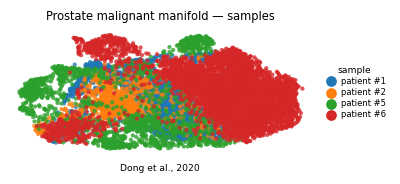

In [13]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Prostate malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Dong et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])